In [154]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [155]:
opens = np.load("data/x_train.npy")

In [156]:
cum_avg = np.cumsum(opens, axis=0)/np.arange(1, opens.shape[0]+1).reshape(-1, 1)
cum_avg

array([[0.        , 0.        , 1.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.5       , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.33333333, ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.01360544, 0.00680272, 0.06122449, ..., 0.01360544, 0.08843537,
        0.19047619],
       [0.01351351, 0.00675676, 0.06081081, ..., 0.01351351, 0.08783784,
        0.18918919],
       [0.01342282, 0.00671141, 0.06040268, ..., 0.01342282, 0.09395973,
        0.18791946]], shape=(149, 130802))

In [157]:
Y = cum_avg.flatten(order='F')
X = np.arange(len(Y)) % len(cum_avg)

In [158]:
Y_cols = Y.reshape(len(cum_avg), -1, order='F')
X_cols = X.reshape(len(cum_avg), -1, order='F')

## Cherry-picking users whose behaviour drifts

Goal: find users for whom the unweighted historic open rate $\phi_j$ is misleading, and the recency-weighted $\phi_j$ (Eq. 3-4) is closer to what they do *now*.
The setup cell below holds every threshold, so patterns can be tuned in one place.

In [159]:
import pandas as pd

n, m = opens.shape                      # n templates (time axis), m users

# ---------- recency weights, Eq. (3)-(4) ----------
H = 0.1                                 # half-life, in fractions of the history (value used in the model)
def recency_weights(n, h):
    d = (n - np.arange(1, n + 1)) / n   # d_i = (n - i) / n
    return 2.0 ** (-d / h)

w = recency_weights(n, H)
phi_unw = opens.mean(axis=0)            # original phi
phi_w   = (w @ opens) / w.sum()         # recency-weighted phi
delta   = phi_w - phi_unw               # >0: user is warming up, <0: user is cooling down

# ---------- pattern thresholds ----------
N_EARLY, K_LATE = 90, 30               # late bloomer / dropout: "early" vs "last K templates"
BLOOM_EARLY_MAX, BLOOM_LATE_MIN = 0.02, 0.50
DROP_EARLY_MIN,  DROP_LATE_MAX  = 0.50, 0.05

PHASES = [0, 50, 100, n]                # 3 phases for on-off-on / off-on-off
ON, OFF = 0.35, 0.15                    # rate counted as "opening" / "not opening" in a phase

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
N_SHOW = 6                              # users shown per pattern


def rate(a, b):
    """Open rate of every user over templates [a, b)."""
    return opens[a:b].mean(axis=0)

In [160]:
# ---------- boolean masks over all m users ----------
early, late = rate(0, N_EARLY), rate(n - K_LATE, n)
head,  tail = rate(0, n - K_LATE), rate(n - K_LATE, n)
p1, p2, p3 = (rate(PHASES[i], PHASES[i + 1]) for i in range(3))

masks = {
    "late bloomer":  (early <= BLOOM_EARLY_MAX) & (late >= BLOOM_LATE_MIN),
    "dropout":       (head >= DROP_EARLY_MIN) & (tail <= DROP_LATE_MAX),
    "on-off-on":     (p1 >= ON)  & (p2 <= OFF) & (p3 >= ON),
    "off-on-off":    (p1 <= OFF) & (p2 >= ON)  & (p3 <= OFF),
}
bounds = {                               # phase boundaries, only used for shading plots
    "late bloomer": [0, N_EARLY, n],
    "dropout":      [0, n - K_LATE, n],
    "on-off-on":    PHASES,
    "off-on-off":   PHASES,
}

print("candidates per pattern:", {k: int(v.sum()) for k, v in masks.items()})


def pick(mask, score, k=N_SHOW):
    """Top-k users of a pattern, ranked by a pattern-specific score (higher = cleaner example)."""
    idx = np.flatnonzero(mask)
    return idx[np.argsort(-score[idx])][:k]


# ranking scores: how clean / extreme the pattern is
score = {
    "late bloomer": late - early,
    "dropout":      head - tail,
    "on-off-on":    np.abs(delta),              # sign depends on how strong the return is
    "off-on-off":   p2 - np.maximum(p1, p3),    # active middle, quiet edges
}

candidates per pattern: {'late bloomer': 116, 'dropout': 704, 'on-off-on': 18, 'off-on-off': 903}


In [161]:
t = np.arange(1, n + 1)

def summary(idx, name):
    b = bounds[name]
    df = pd.DataFrame({
        "user": idx,
        "opens": opens[:, idx].sum(axis=0).astype(int),
        **{f"rate {b[i]}-{b[i+1]}": rate(b[i], b[i + 1])[idx] for i in range(len(b) - 1)},
        "phi (unweighted)": phi_unw[idx],
        f"phi (h={H})": phi_w[idx],
        "delta": delta[idx],
    })
    return df.round(3).set_index("user")


def plot_users(idx, name, ncols=3):
    b = bounds[name]
    nrows = int(np.ceil(len(idx) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 3.3 * nrows),
                             sharex=True, sharey=True, squeeze=False)
    for ax, u in zip(axes.flat, idx):
        for i in range(len(b) - 1):      # shade alternate phases
            if i % 2 == 1:
                ax.axvspan(b[i] + 0.5, b[i + 1] + 0.5, color="0.92", zorder=0)
        ax.plot(t, cum_avg[:, u], c="C0", lw=1.8, label="cumulative open rate")
        ax.axhline(phi_unw[u], c="0.4", ls=":", lw=1.5, label=r"$\phi$ unweighted")
        ax.axhline(phi_w[u],  c="C3",  ls="--", lw=1.5, label=rf"$\phi$ recency-weighted (h={H})")
        opened = t[opens[:, u] == 1]
        ax.vlines(opened, -0.09, -0.02, color="k", lw=0.8)   # raw opens as ticks
        ax.set_ylim(-0.1, 1.03)
        ax.set_title(f"user {u}:  {phi_unw[u]:.2f} -> {phi_w[u]:.2f}", fontsize=10)
    for ax in axes.flat[len(idx):]:
        ax.axis("off")
    for ax in axes[-1]:
        ax.set_xlabel("template")
    for ax in axes[:, 0]:
        ax.set_ylabel("open rate")
    h, l = axes.flat[0].get_legend_handles_labels()
    fig.legend(h, l, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.0))
    fig.suptitle(f"{name}", y=1.04, fontsize=13, fontweight="bold")
    fig.tight_layout()
    plt.show()

### 1. Late bloomer
Almost never opened in the first `N_EARLY` templates, then opens aggressively in the last `K_LATE`.
The unweighted $\phi$ stays low (the quiet past dominates), so the plain model would underrate a user who is now very likely to open.

,opens,rate 0-90,rate 90-149,phi (unweighted),phi (h=0.1),delta
user,,,,,,
17649,44,0.000,0.746,0.295,0.871,0.575
59473,41,0.000,0.695,0.275,0.852,0.577
63448,43,0.000,0.729,0.289,0.863,0.575
103951,43,0.000,0.729,0.289,0.863,0.575
75849,50,0.011,0.831,0.336,0.897,0.561
57755,44,0.011,0.729,0.295,0.863,0.568


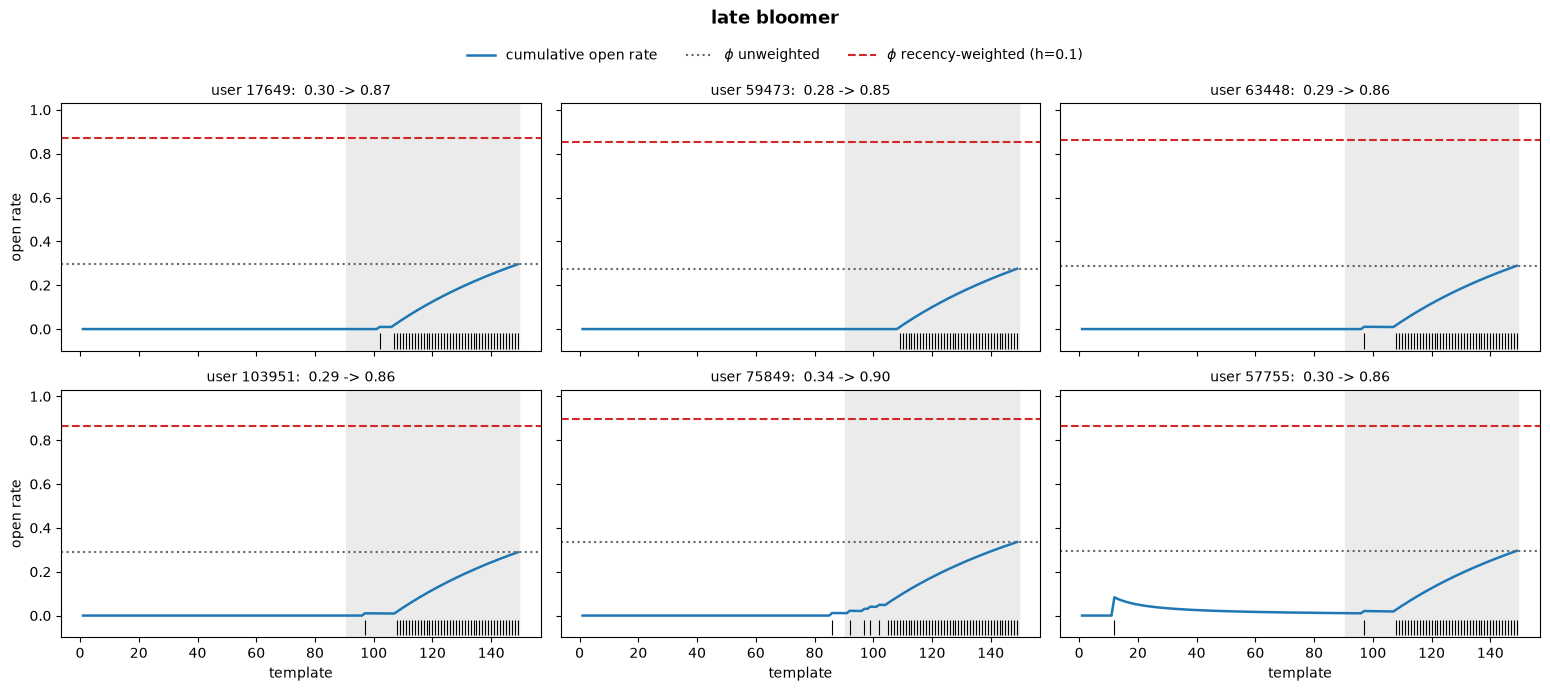

In [162]:
idx_bloom = pick(masks["late bloomer"], score["late bloomer"])
display(summary(idx_bloom, "late bloomer"))
plot_users(idx_bloom, "late bloomer")

### 2. Dropout
Opened a lot until the last `K_LATE` templates, then (almost) stopped.
The unweighted $\phi$ stays high and keeps picking a recipient who has gone quiet.

,opens,rate 0-119,rate 119-149,phi (unweighted),phi (h=0.1),delta
user,,,,,,
26345,103,0.866,0.0,0.691,0.137,-0.554
56735,102,0.857,0.0,0.685,0.145,-0.539
69833,102,0.857,0.0,0.685,0.136,-0.549
56868,100,0.840,0.0,0.671,0.117,-0.554
45377,100,0.840,0.0,0.671,0.127,-0.544
29111,100,0.840,0.0,0.671,0.164,-0.507


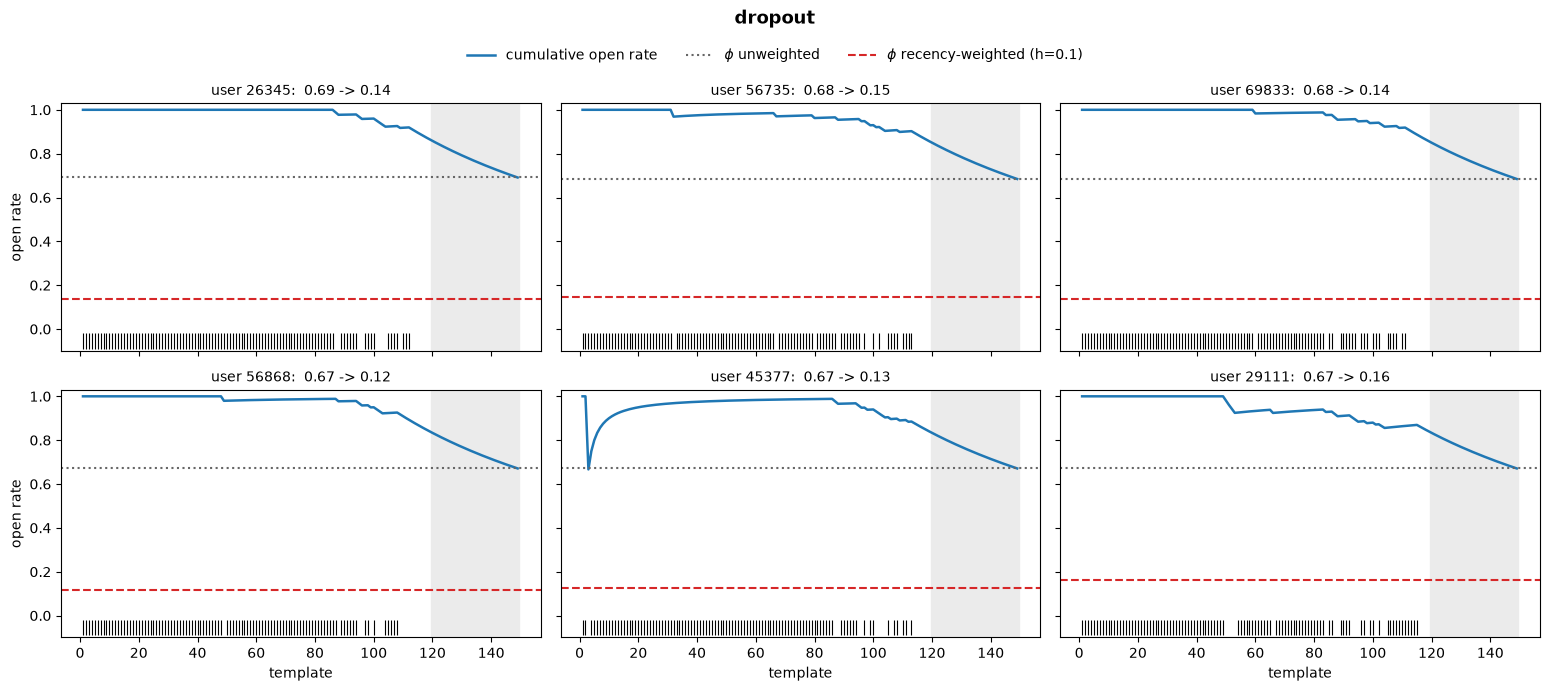

In [163]:
idx_drop = pick(masks["dropout"], score["dropout"])
display(summary(idx_drop, "dropout"))
plot_users(idx_drop, "dropout")

### 3. On → off → on
Opened, stopped, then started opening again (phases are shaded; the middle one is the pause).
The direction of the shift depends on how strong the return is, so users are ranked by $|\Delta\phi|$.

,opens,rate 0-50,rate 50-100,rate 100-149,phi (unweighted),phi (h=0.1),delta
user,,,,,,,
60107,78,0.58,0.10,0.898,0.523,0.891,0.367
54752,40,0.40,0.00,0.408,0.268,0.515,0.247
39791,44,0.38,0.00,0.510,0.295,0.534,0.239
72602,59,0.44,0.10,0.653,0.396,0.564,0.168
93138,50,0.46,0.14,0.408,0.336,0.451,0.115
64799,57,0.58,0.14,0.429,0.383,0.281,-0.102


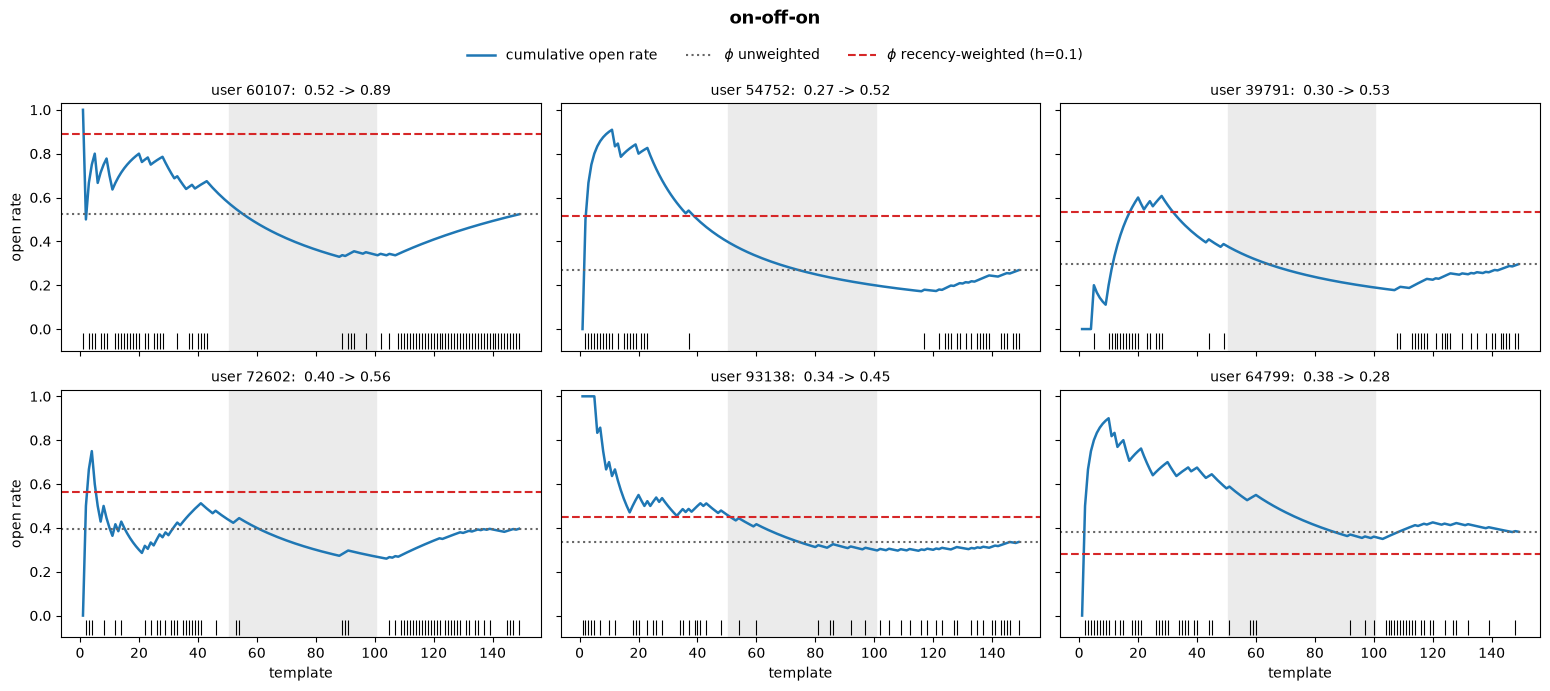

In [164]:
idx_onoffon = pick(masks["on-off-on"], score["on-off-on"])
display(summary(idx_onoffon, "on-off-on"))
plot_users(idx_onoffon, "on-off-on")

### 4. Off → on → off
Quiet, then active for a while, then quiet again. The quiet last phase dominates the recency-weighted $\phi$, which is pulled below the plain average. Ranked by how active the middle phase is relative to the edges.

,opens,rate 0-50,rate 50-100,rate 100-149,phi (unweighted),phi (h=0.1),delta
user,,,,,,,
105279,40,0.0,0.80,0.000,0.268,0.066,-0.203
116243,44,0.0,0.84,0.041,0.295,0.084,-0.212
115058,39,0.0,0.78,0.000,0.262,0.067,-0.195
127572,39,0.0,0.78,0.000,0.262,0.062,-0.199
120538,39,0.0,0.78,0.000,0.262,0.067,-0.195
116168,43,0.0,0.82,0.041,0.289,0.087,-0.202


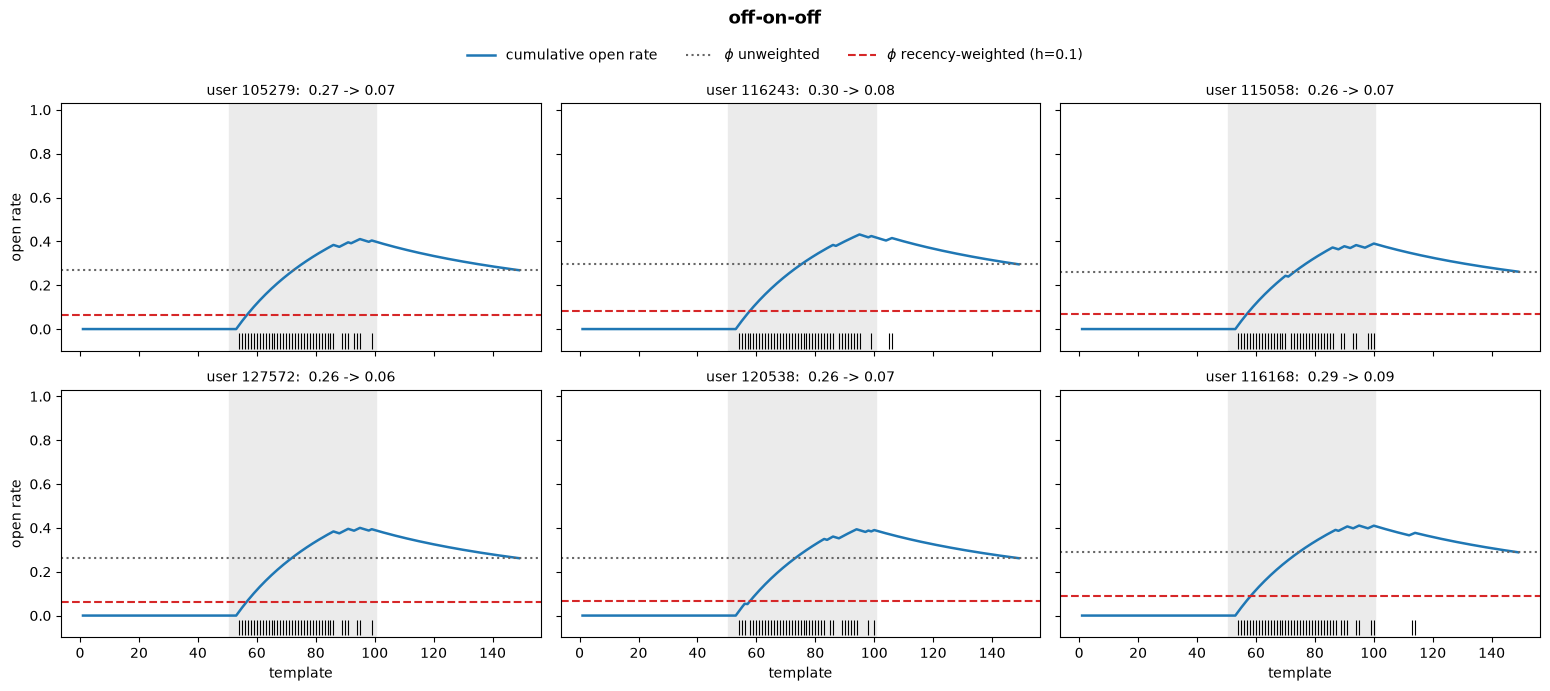

In [165]:
idx_offonoff = pick(masks["off-on-off"], score["off-on-off"])
display(summary(idx_offonoff, "off-on-off"))
plot_users(idx_offonoff, "off-on-off")

### Overview: how much does recency weighting move $\phi$ for each pattern?

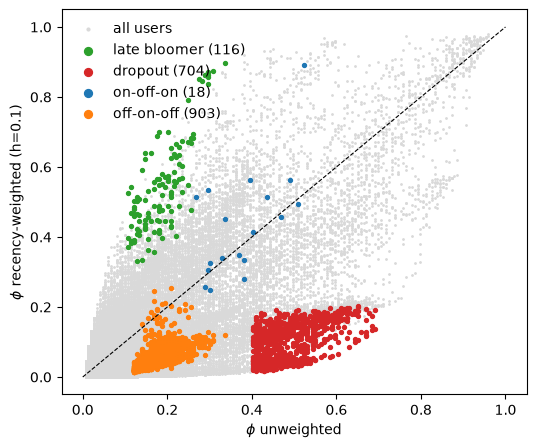

In [166]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(phi_unw, phi_w, s=1, c="0.85", rasterized=True, label="all users")
for (name, mask), c in zip(masks.items(), ["C2", "C3", "C0", "C1"]):
    ax.scatter(phi_unw[mask], phi_w[mask], s=8, c=c, label=f"{name} ({mask.sum()})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlabel(r"$\phi$ unweighted"); ax.set_ylabel(rf"$\phi$ recency-weighted (h={H})")
ax.legend(markerscale=2, frameon=False)
plt.show()

## Paper figure: one panel, all groups
Individual users are drawn from each pattern. The curve is the cumulative open rate (its right end is the unweighted $\phi$); the marker at the right is the recency-weighted $\phi$.

In [ ]:
import os
import matplotlib as mpl

# ---------- figure config ----------
FIG_W, FIG_H = 3.4, 2.7       # inches: single column (use ~6.85 wide for double column)
GROUPS_FIG   = ["late bloomer", "dropout", "on-off-on", "off-on-off"]   # drop one for a 3-group figure
N_PER_GROUP  = 2
PICK, SEED   = "random", 0    # "random": seeded draw from all matching users | "top": cleanest examples
SHOW_GROUP_MEAN = False       # thick translucent mean curve of every matching user

COL_BASE = "#9AA5B1"          # baseline (unweighted phi): neutral grey
COL = {"late bloomer": "#2B6CB0", "dropout": "#C05621",
       "on-off-on": "#2F855A", "off-on-off": "#805AD5"}
LABEL = {"late bloomer": "late bloomer", "dropout": "dropout",
         "on-off-on": r"on$\to$off$\to$on", "off-on-off": r"off$\to$on$\to$off"}

STYLE = {
    "font.family": "serif",
    "font.serif": ["STIXGeneral", "Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 7,
    "axes.labelsize": 7,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "axes.linewidth": 0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "xtick.major.pad": 2,
    "ytick.major.pad": 2,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}


def choose(name, k, mode=PICK, seed=SEED):
    idx = np.flatnonzero(masks[name])
    if mode == "top":
        return idx[np.argsort(-score[name][idx])][:k]
    return np.random.default_rng(seed).choice(idx, size=k, replace=False)

In [205]:
GROUPS_FIG

['late bloomer', 'dropout', 'on-off-on', 'off-on-off']

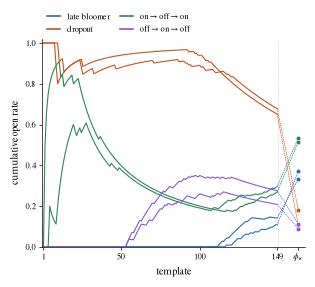

opens  phi (unweighted)  phi (h=0.1)  delta
             user                                               
late bloomer 118145     21             0.141        0.335  0.194
             93863      16             0.107        0.372  0.265
dropout      65210     101             0.678        0.183 -0.495
             25915      97             0.651        0.106 -0.545
on-off-on    54752      40             0.268        0.515  0.247
             39791      44             0.295        0.534  0.239
off-on-off   129066     41             0.275        0.113 -0.163
             123821     31             0.208        0.089 -0.119

In [210]:
# chosen = {g: choose(g, N_PER_GROUP, seed=209) for g in GROUPS_FIG}

chosen = {
    "late bloomer": [118145, 93863],
    "dropout":[65210, 25915],
    "on-off-on":[54752,  39791],
    "off-on-off":[129066, 123821],
}

x_end = n + 0.09 * n                       # x position of the phi_w markers

with mpl.rc_context(STYLE):
    fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))

    for g in GROUPS_FIG:
        if SHOW_GROUP_MEAN:
            ax.plot(t, cum_avg[:, masks[g]].mean(axis=1), color=COL[g], lw=2.2, alpha=0.25, zorder=1)
        for u in chosen[g]:
            ax.plot(t, cum_avg[:, u], color=COL[g], lw=0.8, zorder=2)
            ax.plot([n, x_end], [phi_unw[u], phi_w[u]], color=COL[g], lw=0.5, ls=(0, (2, 1)), zorder=2)
            ax.scatter([x_end], [phi_w[u]], s=10, color=COL[g], edgecolor="white", linewidth=0.3, zorder=3)

    ax.axvline(n + 0.5, color=COL_BASE, lw=0.4, ls=":", zorder=0)
    ax.set_xlim(0, x_end + 0.03 * n)
    ax.set_ylim(0, 1.02)
    ax.set_xticks([1, 50, 100, n, x_end])
    ax.set_xticklabels(["1", "50", "100", str(n), r"$\phi_{w}$"])
    ax.set_xlabel("template")
    ax.set_ylabel("cumulative open rate")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

    handles = [plt.Line2D([], [], color=COL[g], lw=1.2) for g in GROUPS_FIG]
    ax.legend(handles, [LABEL[g] for g in GROUPS_FIG], loc="lower left", bbox_to_anchor=(0, 1.0),
              ncol=2, frameon=False, fontsize=6, handlelength=1.6, columnspacing=1.2,
              borderaxespad=0.2)

    os.makedirs("figures", exist_ok=True)
    fig.savefig("figures/phi_drift.pdf", bbox_inches="tight")
    fig.savefig("figures/phi_drift.png", bbox_inches="tight", dpi=300)
    plt.show()

# what was plotted
pd.concat({g: summary(chosen[g], g)[["opens", "phi (unweighted)", f"phi (h={H})", "delta"]]
           for g in GROUPS_FIG}).round(3)

In [ ]:
[118145, 93863]
[65210, 25915]
[54752, 68384, 64799, 39791]
[129066, 123821]